In [1]:
import sys
import pickle
from pathlib import Path

import pandas as pd
import geopandas as gpd 
import numpy as np
import matplotlib as mp
import matplotlib.pyplot as plt

import config, data, models, train, evaluate

In [2]:
save_dir = Path("/nas/cee-water/cjgleason/ted/swot-ml/data/multigraph_manual")
metadata_dir = save_dir / "metadata"

subbasins = pd.read_parquet(metadata_dir / 'subbasins.parquet', columns=['site_id', 'uparea_km2', 'is_gauge', 'outlet_id'])
subbasins.index = subbasins.index.astype(str)

In [3]:
exp_root = Path("/nas/cee-water/cjgleason/ted/swot-ml/runs/sf_grnn_pooled_dams")
target = 'discharge'

exp_dirs = [p.parent for p in (exp_root).rglob('results/test_results.parquet')] 
exp_dirs

[PosixPath('/nas/cee-water/cjgleason/ted/swot-ml/runs/sf_grnn_pooled_dams/era5_20260518_144850/results'),
 PosixPath('/nas/cee-water/cjgleason/ted/swot-ml/runs/sf_grnn_pooled_dams/swot_20260518_144850/results'),
 PosixPath('/nas/cee-water/cjgleason/ted/swot-ml/runs/sf_grnn_pooled_dams/era5_vae_20260522_180704/results'),
 PosixPath('/nas/cee-water/cjgleason/ted/swot-ml/runs/sf_grnn_pooled_dams/swot_vae_20260527_154025/results')]

In [4]:
exp_root =  Path("/nas/cee-water/cjgleason/ted/swot-ml/runs/sf_grnn_MS_pooled/")
target = 'discharge'

exp_dirs = [
    "/nas/cee-water/cjgleason/ted/swot-ml/runs/sf_grnn_MS_pooled/swot_20260401_204203",
    "/nas/cee-water/cjgleason/ted/swot-ml/runs/sf_grnn_pooled/swot_20260504_193818",
]
exp_dirs = [Path(d) / 'results' for d in exp_dirs]
exp_dirs

[PosixPath('/nas/cee-water/cjgleason/ted/swot-ml/runs/sf_grnn_MS_pooled/swot_20260401_204203/results'),
 PosixPath('/nas/cee-water/cjgleason/ted/swot-ml/runs/sf_grnn_pooled/swot_20260504_193818/results')]

In [4]:
def calc_discharge(df, subs):
    uparea = subs['uparea_km2'] 
    mapped_uparea = df.index.get_level_values('subbasin').map(uparea)
    
    df[('pred', 'discharge')] = df[('pred','unit_discharge')] * mapped_uparea
    df[('obs', 'discharge')] = df[('obs','unit_discharge')] * mapped_uparea
    return df

In [4]:
fig_dir = exp_root / "_figures"
fig_dir.mkdir(exist_ok=True, parents=True)

from tqdm import tqdm
import evaluate

exps = []
for exp_dir in tqdm(exp_dirs):
    try:
        exp_name = ' '.join(exp_dir.parent.stem.split('_')[:-2])
        
        results = pd.read_parquet(exp_dir / 'test_results.parquet').dropna()

        bulk_m = evaluate.get_all_metrics(results)
        basin_m = evaluate.get_basin_metrics(results)

        # if 'unit_discharge' in results['pred'].columns:
        #     results = calc_discharge(results, subbasins)
        #     bulk_m = evaluate.get_all_metrics(results)
        #     basin_m = evaluate.get_basin_metrics(results)
        # else:
        #     with open(exp_dir / "test_metrics.pkl", 'rb') as f:
        #         bulk_m, basin_m = pickle.load(f)
        
        exps.append((exp_name, results, bulk_m, basin_m))
    except Exception as e:
        print(f"{exp_name}: {e}")
        pass

exps = sorted(exps, key=lambda x: x[0])

100%|██████████| 4/4 [00:47<00:00, 11.99s/it]


In [20]:
exps[1][2]

{'unit_discharge': {'num_obs': 0,
  'R2': nan,
  'r': nan,
  'NSE': nan,
  'sigE': nan,
  'rRMSE': nan,
  'MAPE': nan,
  'nBias': nan,
  'RE': nan,
  'RB': nan,
  'Agreement': nan,
  'KGE': nan,
  'corr': nan,
  'alpha': nan,
  'beta': nan,
  'nse_prob': nan,
  'MSESS': nan}}

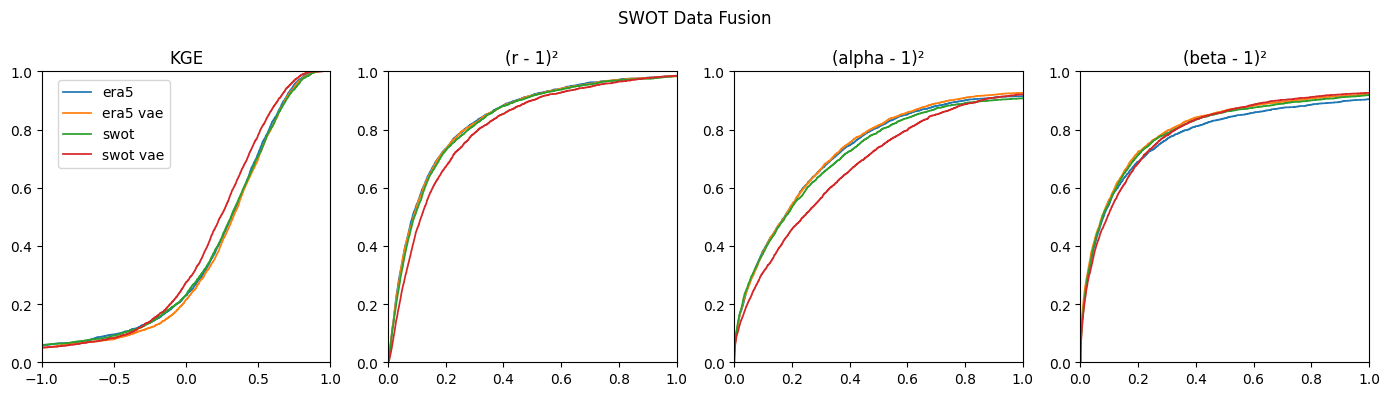

In [9]:
plt.close('all')

target = 'discharge'
num_models = len(exps)

metric_names = {
    # 'MSESS': 'MSESS',
    # 'nse_prob': 'NSE prob',
    # 'NSE': 'NSE',
    'KGE': 'KGE',
    'corr': '(r - 1)²',
    'alpha': '(alpha - 1)²',
    'beta': '(beta - 1)²'
}

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
axes = axes.flatten()

for ax, (name, title) in zip(axes, metric_names.items()):
    for exp_name, results, bulk_metrics, basin_metrics in exps:
        x = np.array(basin_metrics[target][name], dtype=float)
        
        if name in ['alpha', 'beta', 'corr']:
            x = (x-1)**2
        
        x = x[~np.isnan(x)]
        if len(x)<10:
            continue
        ax.ecdf(x, linewidth=1.25, label=exp_name)
    
    ax.set_title(f"{title}")

axes[0].set_xlim([-1, 1])
axes[1].set_xlim([0, 1])
axes[2].set_xlim([0, 1])
axes[3].set_xlim([0, 1])

handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='upper left', bbox_to_anchor=(0.04, 0.82))

# fig.subplots_adjust(left=0.1, right=0.95, bottom=0.2, top=0.95, wspace=0.3, hspace=0.4)
plt.suptitle('SWOT Data Fusion')
plt.tight_layout()
plt.show()

# fig.savefig(fig_dir / f"KGE_comp.png", dpi=300)

In [6]:
exps[0][1]

pred                       obs
                                          discharge discharge_std   discharge
basin         subbasin      date                                             
USGS-07374000 ECCC-11AA025  2023-04-01     6.780354      9.456099    2.220000
              USGS-03017500 2023-04-01    30.074463     31.267941   37.944572
              USGS-03024000 2023-04-01   208.328644    165.376587  142.433746
              USGS-03029500 2023-04-01    91.069252     76.243423  108.453514
              USGS-03030500 2023-04-01   160.774216    124.240166  124.027786
...                                             ...           ...         ...
              USGS-07249455 2025-12-31  1418.955688   1228.017822  223.986298
              USGS-07263115 2025-12-31     2.537615      4.932124    6.682775
              USGS-07276000 2025-12-31     4.172971      7.363528    1.968021
              USGS-07289730 2025-12-31     8.398441     10.433644    8.240201
              USGS-07295000 2025-12-31     2.439637      5.026631    1.209129

[429103 rows x 3 columns]

In [9]:
import xarray as xr

basin_mask = (subbasins['outlet_id'] == 'USGS-07374000')
test_sub_mask = subbasins.index.isin(results.index.get_level_values('subbasin').unique())
basin_gauges = subbasins[basin_mask & test_sub_mask].index
basin_ds = xr.open_zarr("/scratch4/workspace/tlanghorst_umass_edu-swot-ml-zarr/zbs_batched/USGS-07374000")
gauge_ds = basin_ds.sel(subbasin=basin_gauges)


# ds = ds.sel(subbasin=reach_id, date=slice(start_date, end_date))
# has_swot_obs = ~np.isnan(ds['d_wse_river'].to_numpy())

In [10]:
gauge_swot_count = (~gauge_ds['d_wse_river'].to_dataframe().isna()).groupby('subbasin').apply(np.sum, axis=0)
gauge_swot_count.sort_values(by='d_wse_river', inplace=True)

In [11]:
gauge_swot_count

,d_wse_river
subbasin,
USGS-06076690,0
USGS-06470000,0
USGS-06464500,0
USGS-06452320,0
USGS-06450500,0
...,...
USGS-06438000,70
USGS-06784000,84
USGS-06478500,85


(-0.5, 0.5)

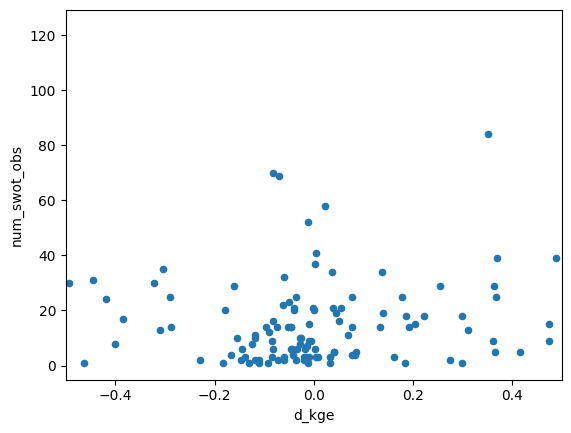

In [12]:
metric = 'NSE'

joined_kge = exps[0][3][target][metric].rename('era5').to_frame().join(exps[1][3][target][metric].rename('swot'))
joined_kge['d_kge'] = joined_kge['swot'] - joined_kge['era5'] 
joined_kge = joined_kge.join(gauge_swot_count.rename(columns={'d_wse_river':'num_swot_obs'}))
joined_kge = joined_kge[joined_kge['num_swot_obs']>0]

joined_kge.plot.scatter('d_kge','num_swot_obs')
plt.xlim([-0.5, 0.5])

In [39]:
kge = exps[1][3][target]['MSESS'].dropna().sort_values(ascending=False)

kge[kge>0]

Series([], Name: MSESS, dtype: object)

In [12]:
exps[1][3][target]

Metric,num_obs,R2,r,NSE,sigE,rRMSE,MAPE,nBias,RE,RB,Agreement,KGE,corr,alpha,beta,nse_prob,MSESS
ABOM-1032010,604,-4.258165,0.507535,-4.258165,0.617291,164.620674,1.648643,1.377383,138.499022,137.738323,0.424492,-1.084294,0.702736,2.759496,2.077075,-323.067902,-161.033949
ABOM-104474010,336,-0.208524,0.325731,-0.208524,0.631017,192.245078,0.611026,-0.26962,82.359254,-36.916327,0.020855,-0.329811,0.143586,0.089635,0.54592,-0.800017,0.099991
ABOM-104537010,243,0.04096,0.438871,0.04096,0.584906,127.146661,0.849371,0.36059,84.01885,36.058962,0.075916,-0.135348,0.249005,0.158205,0.871929,-1.095455,-0.047727
ABOM-105032010,102,-0.47886,0.047543,-0.47886,0.439306,67.627352,1.289888,1.12961,123.411703,112.94713,0.064568,-0.257584,0.168071,0.303673,1.636036,-6.391089,-2.695545
ABOM-11537010,1005,-2.167179,0.679182,-2.167179,1.200213,200.967383,0.574061,-0.184156,44.172525,-22.57247,0.567643,-0.806011,0.840193,2.474553,2.030451,-2378.619873,-1188.809926
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
USGS-50024950,999,-8.828062,0.55734,-8.828062,0.420495,209.980369,0.688889,0.253415,56.499541,25.341475,0.197874,-1.441687,0.363627,3.333709,1.332665,-508.783417,-253.891703
USGS-50026025,704,-0.028764,0.578755,-0.028764,0.464443,94.848698,1.48865,1.396338,147.192669,139.633369,0.144427,-0.131376,0.349628,0.248353,1.540422,-2.441428,-0.720714
USGS-50055000,994,0.052473,0.663611,0.052473,0.45291,204.346752,0.748461,0.302717,63.522744,30.271697,0.237234,0.12503,0.302382,0.487294,0.873375,-2.288828,-0.644414
USGS-50056400,306,-0.023598,0.281377,-0.023598,0.546846,109.660399,1.306873,1.19823,141.402745,119.822001,0.034838,-0.257838,0.153031,0.120718,1.302759,-1.610182,-0.305091


In [13]:
joined_kge['d_kge'].sort_values()

USGS-06102050   -95.864552
USGS-07138000   -72.945816
USGS-06680500    -50.31431
USGS-07074500   -46.088923
USGS-07228000   -11.970759
USGS-06336000    -8.874082
USGS-06227600    -6.386405
USGS-07241000    -4.979712
USGS-06857100    -4.847386
USGS-05551540    -4.128412
USGS-07260800    -3.205238
USGS-03048500    -2.969039
USGS-06447450      -1.9722
USGS-06065500    -1.573063
USGS-07196500    -1.530201
USGS-05488500    -1.419875
USGS-06888350    -1.333718
USGS-05595000    -1.021903
USGS-05270700     -0.83804
USGS-03503000    -0.793584
USGS-05344500    -0.730535
USGS-05488110    -0.723014
USGS-06770200    -0.627598
USGS-05418500    -0.555671
USGS-07194500    -0.493543
USGS-03324095    -0.401832
USGS-07241550    -0.391215
USGS-03155000    -0.357072
USGS-05421000    -0.339464
USGS-05476750     -0.31544
USGS-06888990    -0.241952
USGS-05421740    -0.209468
USGS-03284500    -0.198034
USGS-03253500    -0.180023
USGS-06879100    -0.178314
USGS-06837000    -0.169885
USGS-03262700    -0.160385
U

0

20
swot: -0.99
swot: 0.20


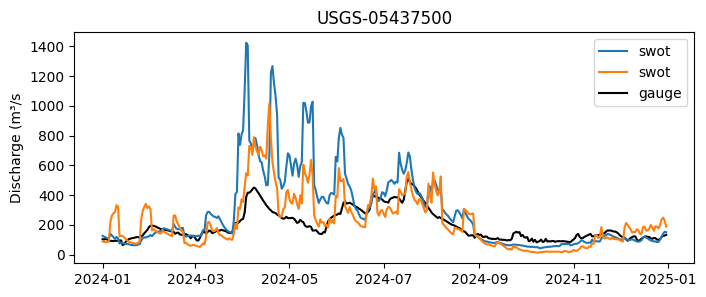

In [14]:
import xarray as xr

reach_id = 'USGS-05437500'
start_date = "2024-01-01"
end_date = "2024-12-31"
metric = 'KGE'

# Horrible hackishness
basin_id = subbasins.loc[reach_id]['outlet_id']
basin_ds = xr.open_zarr(f"/scratch4/workspace/tlanghorst_umass_edu-swot-ml-zarr/zbs_batched/{basin_id}")
subbasin_ds = basin_ds.sel(subbasin=reach_id, date=slice(start_date, end_date))
has_swot_obs = ~np.isnan(subbasin_ds['d_wse_river'].to_numpy())

print(np.sum(has_swot_obs))

fig, ax = plt.subplots(1, 1, figsize=(8, 3))

for exp_name, results, bulk_metrics, basin_metrics in exps: 
    xs = results.xs(reach_id, level='subbasin').sort_index()
    xs = xs.droplevel(0,0)
    xs = xs.loc[start_date:end_date]

    x = xs.index
    y = xs['pred'][target]
    plt.plot(x, y, label=exp_name)
    
    print(f"{exp_name}: {basin_metrics.loc[reach_id][target][metric]:0.2f}")
    
ax.plot(xs.index, xs['obs'][target], color='black', zorder=0, label='gauge')

plt.legend()
plt.title(reach_id)
plt.ylabel("Discharge (m³/s")
plt.show()
# fig.savefig(fig_dir / f"timeseries_{reach_id}.png", dpi=300)

In [41]:
gauge_swot_count = gauge_swot_count.sort_values(by='d_wse_river', ascending=False)

In [42]:

reach_ds = ds.sel(subbasin=reach_id, date=slice(start_date, end_date))
date = reach_ds.date.values
d_wse = reach_ds['d_wse_river'].values
# plt.scatter(date,d_wse)

NameError: name 'ds' is not defined

In [43]:
kge = exps[1][3][target]['KGE'].dropna().sort_values(ascending=False)

# kge[kge>0]

((0.12156862745098039, 0.4666666666666667, 0.7058823529411765),
 (1.0, 0.4980392156862745, 0.054901960784313725),
 (0.17254901960784313, 0.6274509803921569, 0.17254901960784313),
 (0.8392156862745098, 0.15294117647058825, 0.1568627450980392),
 (0.5803921568627451, 0.403921568627451, 0.7411764705882353),
 (0.5490196078431373, 0.33725490196078434, 0.29411764705882354),
 (0.8901960784313725, 0.4666666666666667, 0.7607843137254902),
 (0.4980392156862745, 0.4980392156862745, 0.4980392156862745),
 (0.7372549019607844, 0.7411764705882353, 0.13333333333333333),
 (0.09019607843137255, 0.7450980392156863, 0.8117647058823529))

USGS-06770200: 69
swot: 0.02
swot: 0.24


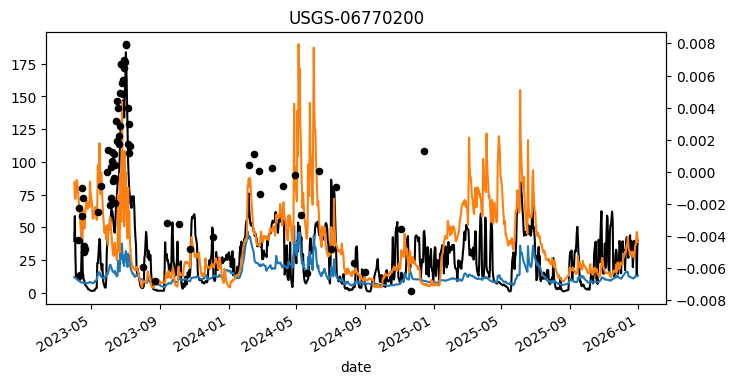

USGS-06336000: 58
swot: 0.01
swot: -2.20


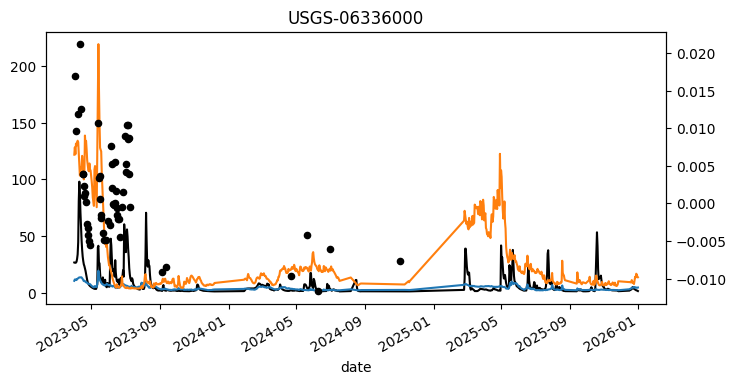

USGS-05344500: 32
swot: 0.08
swot: -0.11


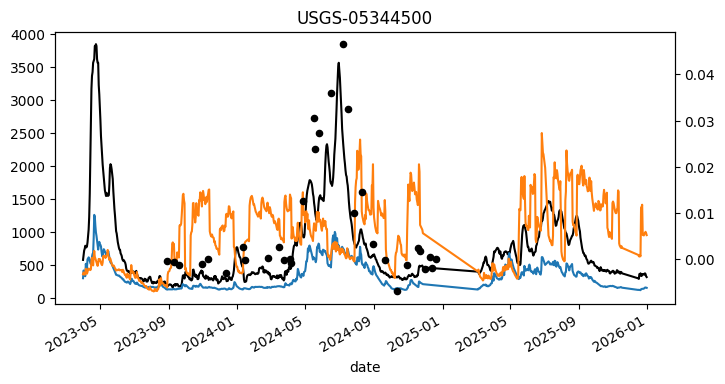

USGS-06888350: 29
swot: 0.37
swot: 0.14


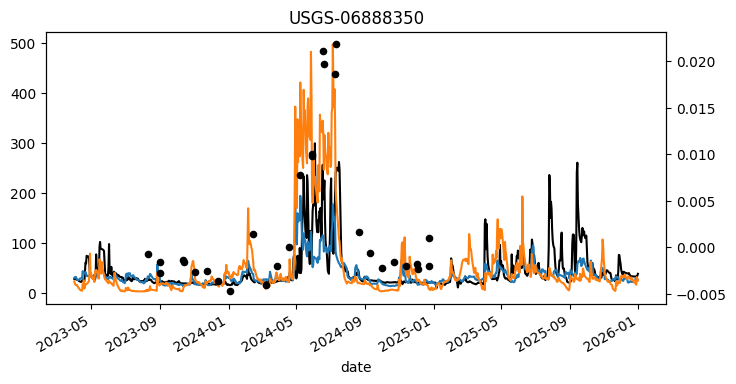

USGS-07260800: 29
swot: -0.04
swot: -0.30


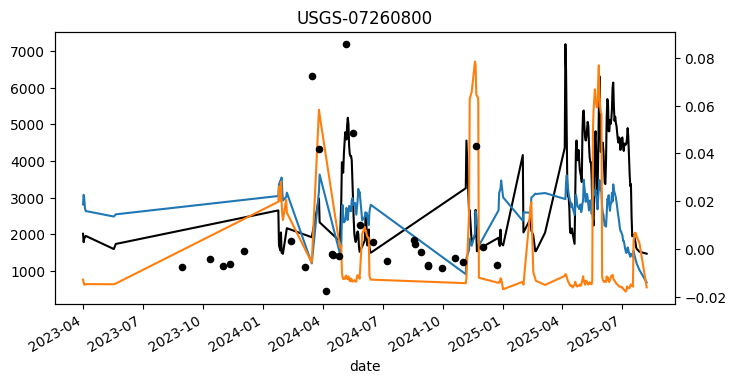

USGS-05437500: 26
swot: -0.99
swot: 0.20


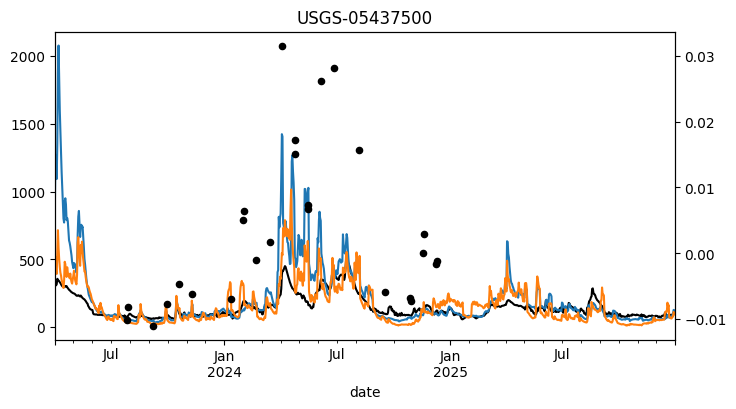

USGS-07194500: 25
swot: 0.74
swot: 0.13


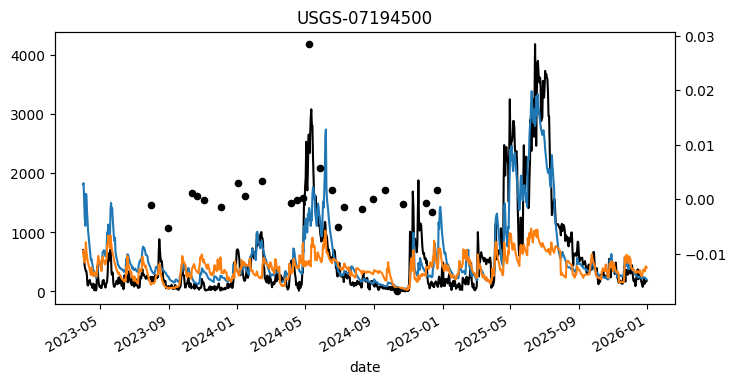

USGS-06065500: 24
swot: 0.38
swot: 0.11


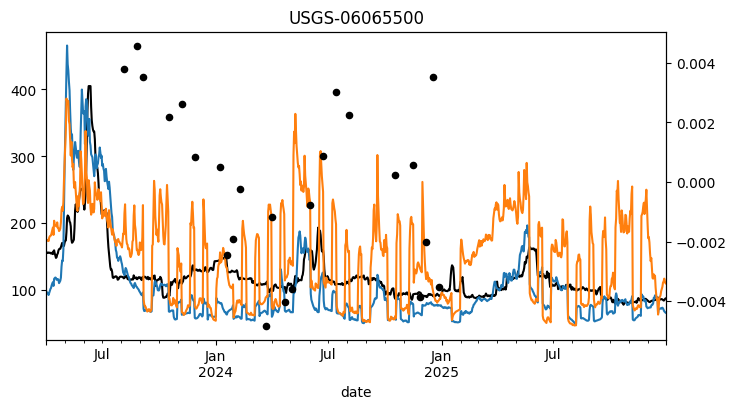

USGS-06102050: 23
swot: -0.80
swot: -6.08


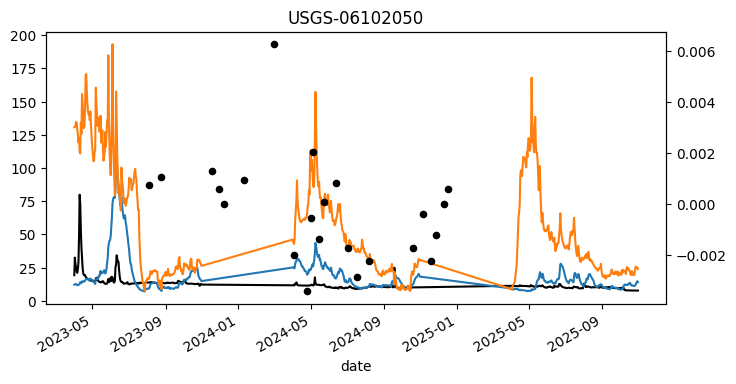

USGS-07074500: 19
swot: 0.17
swot: -4.96


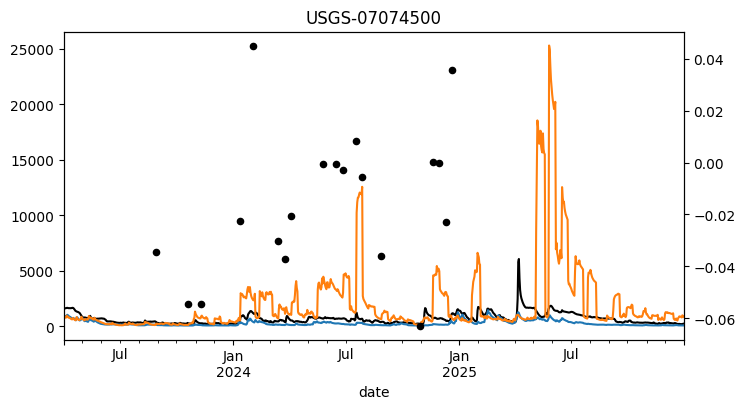

USGS-06888990: 18
swot: 0.44
swot: 0.54


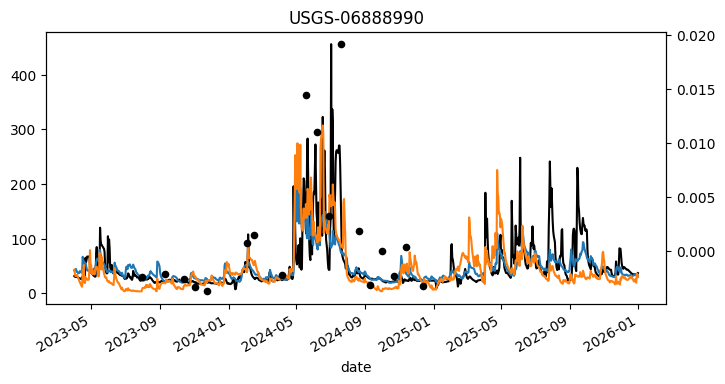

USGS-05242300: 18
swot: 0.37
swot: 0.58


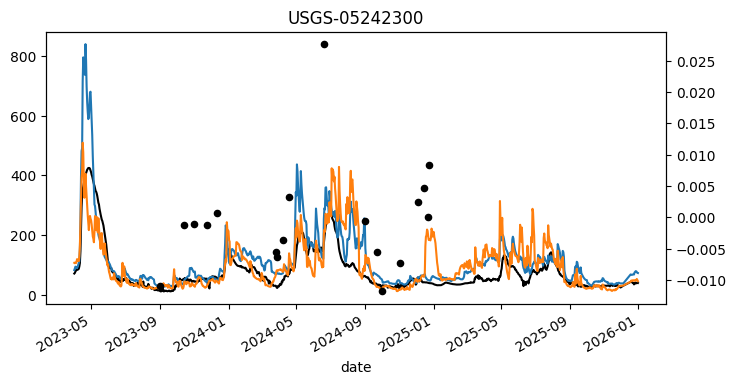

USGS-05270700: 14
swot: 0.58
swot: 0.21


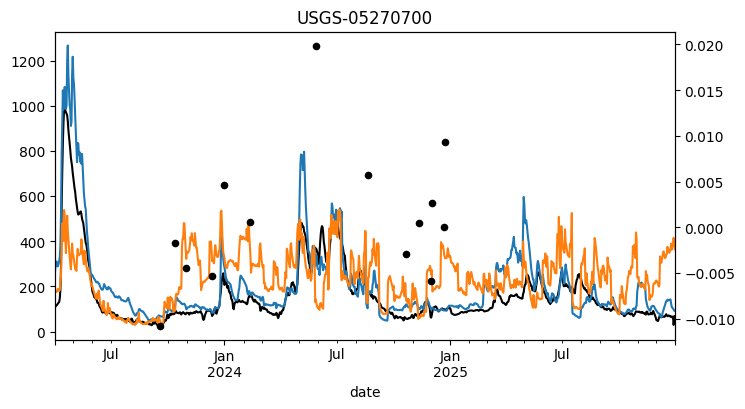

USGS-06879100: 14
swot: 0.05
swot: 0.03


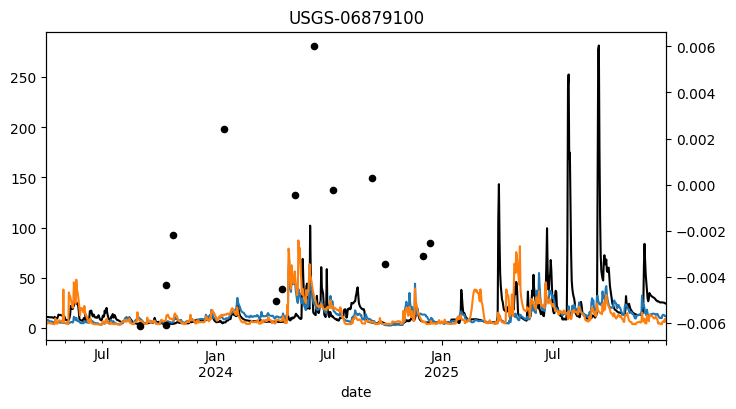

USGS-05488110: 14
swot: 0.80
swot: 0.16


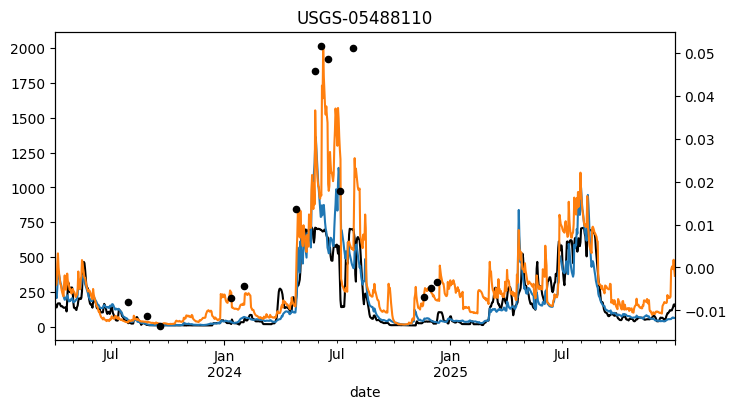

USGS-05595000: 14
swot: 0.47
swot: -0.02


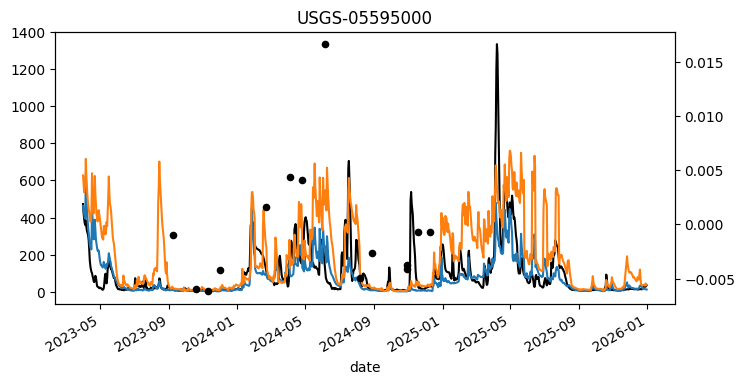

USGS-05488500: 14
swot: 0.76
swot: -0.15


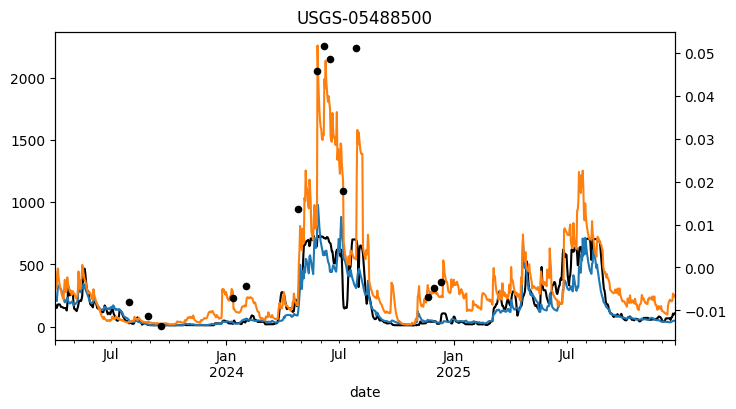

USGS-05476750: 13
swot: 0.37
swot: 0.42


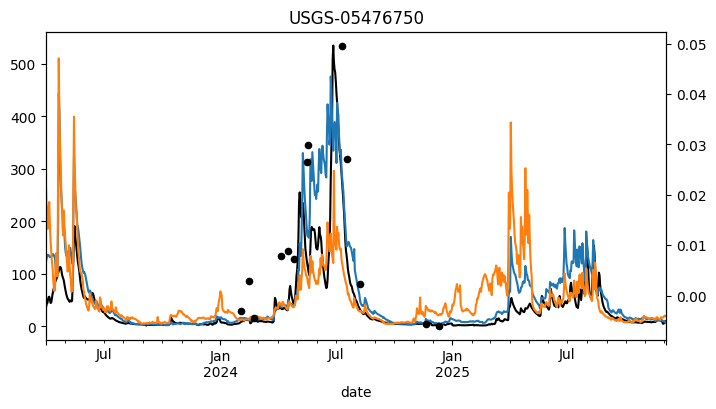

USGS-07138000: 13
swot: 0.60
swot: -6.69


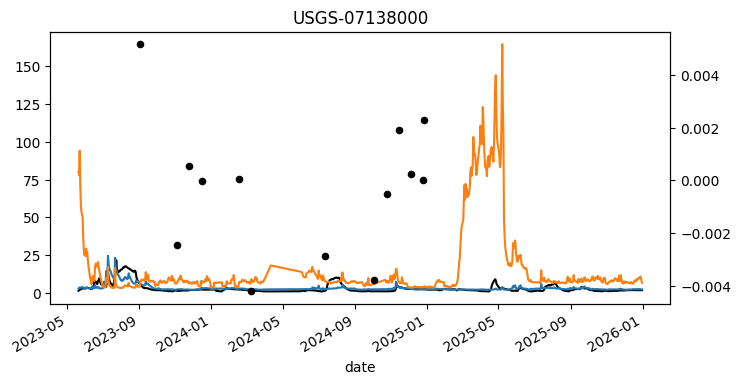

USGS-07228000: 11
swot: 0.01
swot: -1.93


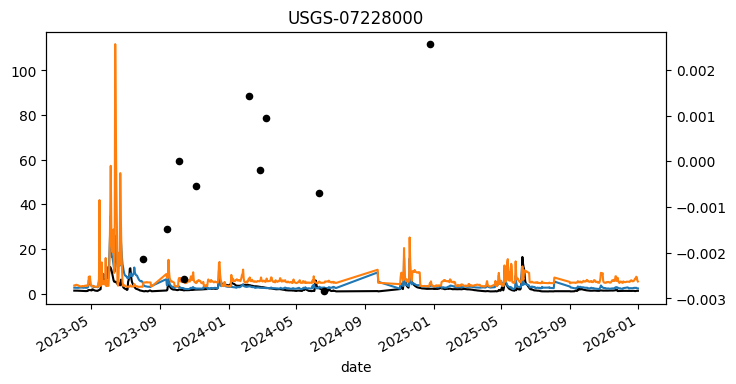

In [15]:
metric = 'KGE'
target='discharge'
start_date = '2023-01-01'
end_date = '2025-12-31'
# colors = ['tab:blue','tab:orange']
colors = plt.get_cmap('tab10').colors

zbs_root = Path("/scratch4/workspace/tlanghorst_umass_edu-swot-ml-zarr/zbs_batched/")

for reach_id, row in joined_kge.sort_values('num_swot_obs', ascending=False).iloc[0:20].iterrows():

    basin_id = subbasins.loc[reach_id]['outlet_id']
    basin_ds = xr.open_zarr(zbs_root / basin_id)
    
    fig, ax = plt.subplots(1, 1, figsize=(8, 4))

    print(f"{reach_id}: {row['num_swot_obs']:.0f}")

    for (exp_name, results, bulk_metrics, basin_metrics), color in zip(exps, colors): 
        x = results.xs(reach_id, level='subbasin').sort_index()
        x = x.droplevel(0,0)
        x = x.loc[start_date:end_date]
        x['pred'][target].plot(ax=ax, color = color, label=exp_name)
        print(f"{exp_name}: {basin_metrics.loc[reach_id][target][metric]:0.2f}")

    x['obs'][target].plot(color='black', ax=ax, zorder=0, label='gauge')

    ax2 = ax.twinx()  # shares x axis but has its own y axis
    
    reach_ds = basin_ds.sel(subbasin=reach_id, date=slice(start_date, end_date))
    date = reach_ds.date.values
    d_wse = reach_ds['d_wse_river'].values / 50
    ax2.scatter(date, d_wse, color='black', s=20, zorder=10, label='d_wse')
        
    
    # plt.legend()
    plt.title(reach_id)
    plt.show()

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6))

exp_idx = 1
name = exps[exp_idx][0]

x = exps[exp_idx][1]['obs'][target]
y = exps[exp_idx][1]['pred'][target]
positive_mask = (x > 0) & (y > 0)
x = x[positive_mask]
y = y[positive_mask]

min_val = 5E-2
max_val = 5E4
log_min = np.log10(min_val)
log_max = np.log10(max_val)

hb = ax.hexbin(x, y, gridsize=(50,50), bins='log', mincnt=5,
            linewidth=0.1,
            extent=(log_min, log_max, log_min, log_max),
            xscale='log', yscale='log')
plt.colorbar(hb, shrink=0.6, aspect=10, anchor=(0,0.5))

# Add a 1:1 line over the min and max of x and y
ax.plot([min_val, max_val], [min_val, max_val], 'k--', linewidth=1.5)

# Setting axes to be square and equal range
ax.axis('square')
ax.set_xlim(min_val, max_val)
ax.set_ylim(min_val, max_val)
ax.set_title(f"{name}: Discharge (n {len(x):,})")
ax.set_xlabel(f'Observed [m3/s]')
ax.set_ylabel(f'Predicted [m3/s]')
plt.show()

# fig.savefig(fig_dir / f"{name}_bulk_scatterplots.png", dpi=300)